<a href="https://colab.research.google.com/github/JannatLima/customer-churn-prediction/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction Using Machine Learning

## 1. Project Overview

Customer churn occurs when customers stop using a company's products or services.

The objective of this project is to develop machine learning models that can predict whether a customer is likely to leave a telecommunications company.

## 2. Objectives

- Explore and understand customer data.
- Perform exploratory data analysis (EDA).
- Clean and preprocess the dataset.
- Identify important factors associated with customer churn.
- Train and compare different machine learning models.
- Evaluate model performance.
- Interpret model predictions.

## 3. Dataset

We use the IBM Telco Customer Churn sample dataset.

## 4. Machine Learning Algorithms

- Logistic Regression
- Random Forest
- XGBoost

## 5. Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

In [2]:
# Import essential libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Set visualization style
sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Dataset URL
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Load dataset
df = pd.read_csv(url)

# Display first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Check number of rows and columns

print("Dataset Shape:", df.shape)

print("Number of Customers:", df.shape[0])
print("Number of Features:", df.shape[1] - 1)

Dataset Shape: (7043, 21)
Number of Customers: 7043
Number of Features: 20


In [5]:
# Display the first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# Display the last five records
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [7]:
# Display column names
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [8]:
# Check data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
# Count missing values in each column
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [10]:
# Check blank values in TotalCharges
print("Blank TotalCharges:",
      (df['TotalCharges'].astype(str).str.strip() == '').sum())

Blank TotalCharges: 11


In [11]:
# Statistical summary of numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [12]:
# Count customers in each churn category
print(df['Churn'].value_counts())

# Calculate percentage distribution
print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


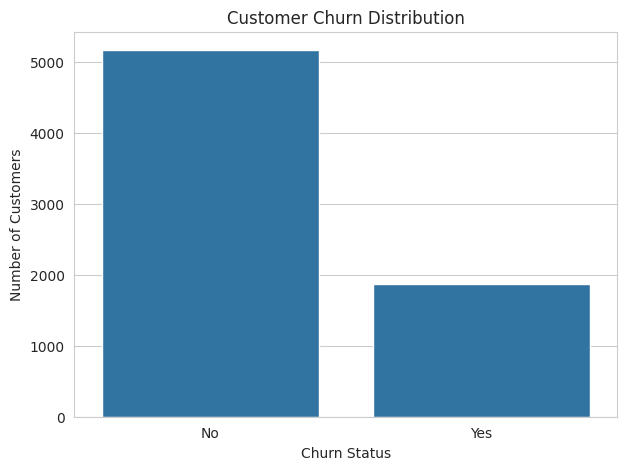

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

In [14]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Working dataset created:", df_clean.shape)

Working dataset created: (7043, 21)


In [15]:
# Convert TotalCharges to numeric
# Invalid or blank values will become NaN

df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'],
    errors='coerce'
)

# Check missing values again
print("Missing TotalCharges:",
      df_clean['TotalCharges'].isnull().sum())

Missing TotalCharges: 11


In [16]:
# Display customers with missing TotalCharges

df_clean.loc[
    df_clean['TotalCharges'].isnull(),
    ['tenure', 'MonthlyCharges', 'TotalCharges']
]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [18]:
df_clean.loc[
    df_clean['TotalCharges'].isnull(),
    'tenure'
].value_counts()

,count
tenure,
0,11


In [19]:
# Replace missing TotalCharges with zero
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

# Verify
print("Remaining missing values:",
      df_clean['TotalCharges'].isnull().sum())

Remaining missing values: 0


In [20]:
# Remove customerID
df_clean.drop('customerID', axis=1, inplace=True)

print("Updated dataset shape:", df_clean.shape)

Updated dataset shape: (7043, 20)


In [24]:
print("Duplicate records:", df_clean.duplicated().sum())

Duplicate records: 22


In [25]:
# Display duplicate records
duplicates = df_clean[df_clean.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicates))

duplicates.head(10)

Total duplicate rows: 42


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
22,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
100,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.20,No
542,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
646,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
662,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
690,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,No
964,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
976,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,Yes
1243,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,45.30,45.30,Yes
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes


In [26]:
# Examine churn distribution among duplicate records
duplicates['Churn'].value_counts()

,count
Churn,
Yes,24
No,18


In [27]:
# Check duplicates in the original dataset,
# including customerID

print("Duplicates in original dataset:",
      df.duplicated().sum())

Duplicates in original dataset: 0


In [28]:
print("Unique customer IDs:", df['customerID'].nunique())
print("Total records:", len(df))

Unique customer IDs: 7043
Total records: 7043


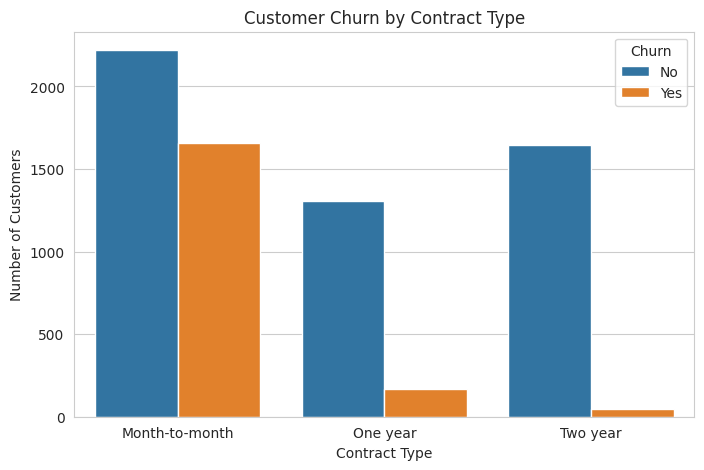

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='Contract',
    hue='Churn'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

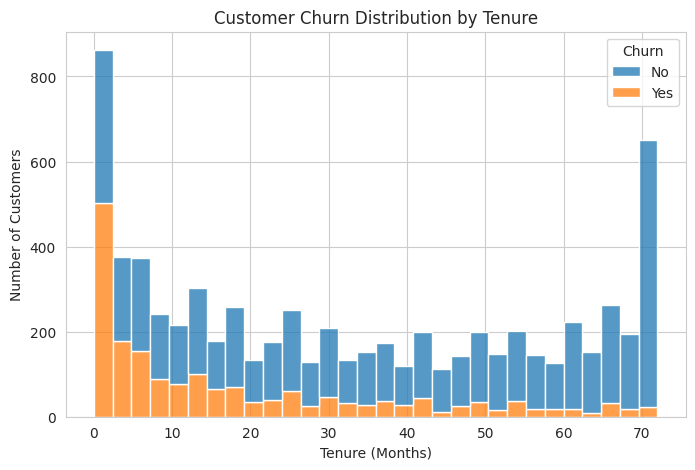

In [30]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='tenure',
    hue='Churn',
    bins=30,
    multiple='stack'
)

plt.title('Customer Churn Distribution by Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

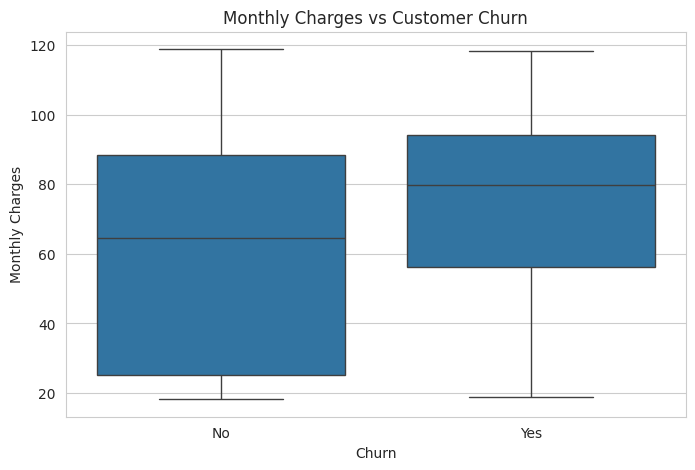

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

In [32]:
contract_churn = pd.crosstab(
    df_clean['Contract'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


### Key Finding 1: Contract Type and Customer Churn

Contract type shows a strong association with customer churn.

The month-to-month contract group has a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.

This indicates that customers with month-to-month contracts are substantially more likely to leave the company.

Contract type may therefore be an important feature for predicting customer churn.

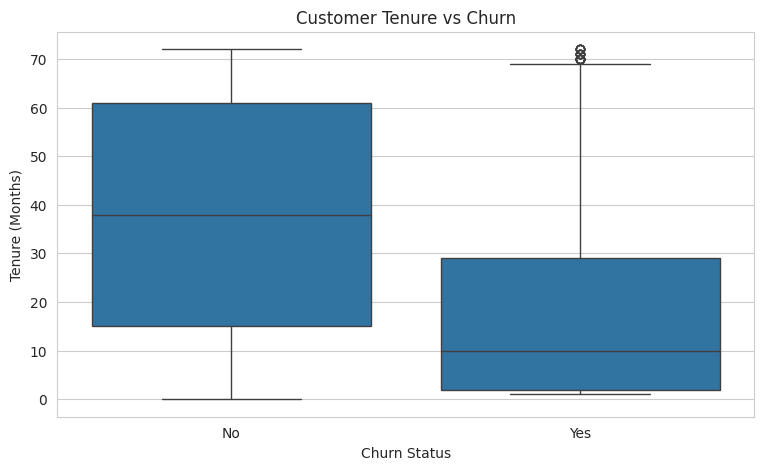

In [33]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='Churn',
    y='tenure'
)

plt.title('Customer Tenure vs Churn')
plt.xlabel('Churn Status')
plt.ylabel('Tenure (Months)')

plt.show()

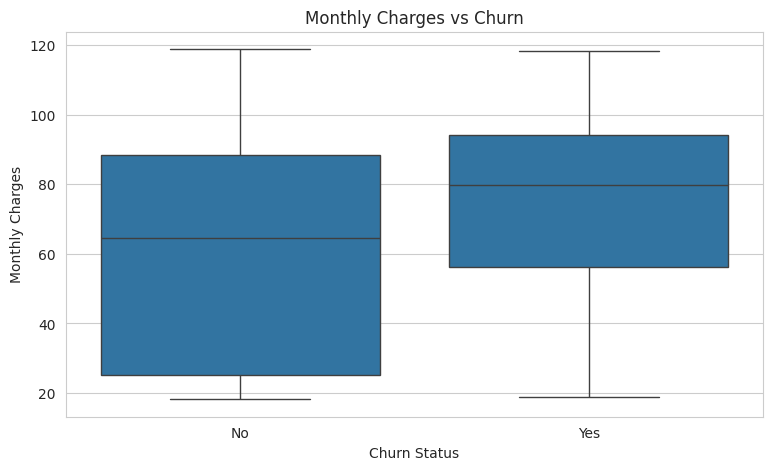

In [34]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.show()

In [35]:
# Compare average tenure and monthly charges
df_clean.groupby('Churn')[
    ['tenure', 'MonthlyCharges', 'TotalCharges']
].mean().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


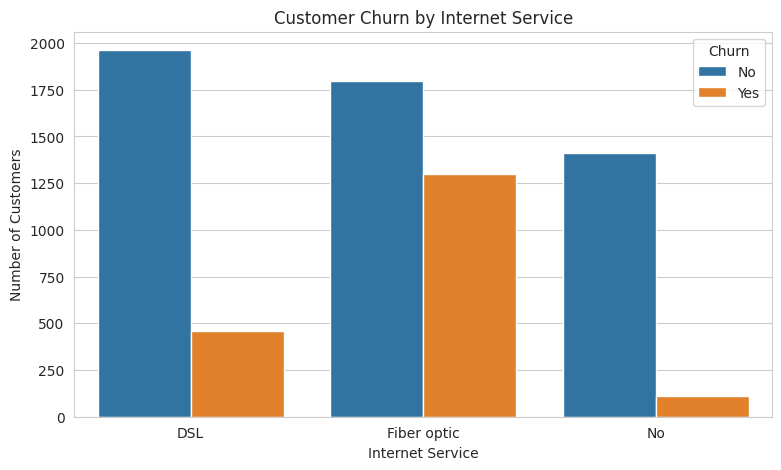

In [36]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='InternetService',
    hue='Churn'
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')

plt.show()

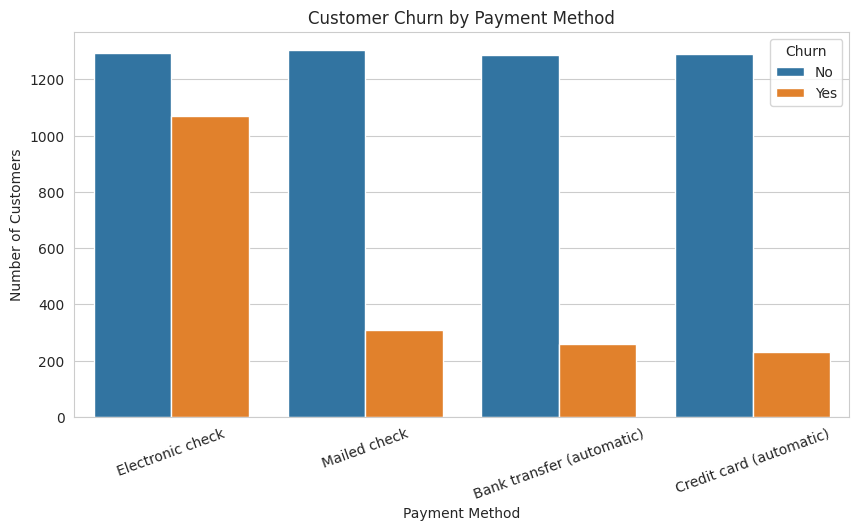

In [37]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')

plt.xticks(rotation=20)
plt.show()

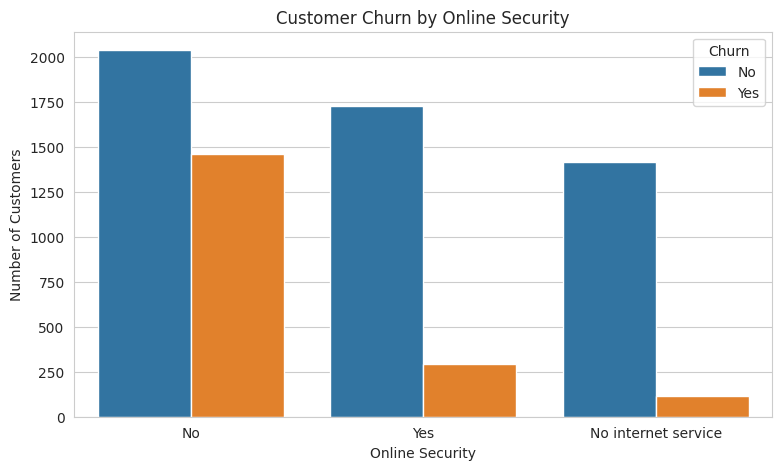

In [38]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='OnlineSecurity',
    hue='Churn'
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')

plt.show()

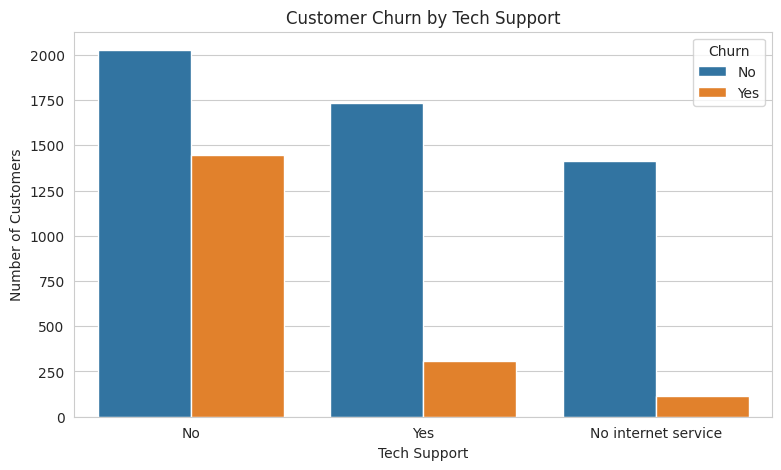

In [39]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='TechSupport',
    hue='Churn'
)

plt.title('Customer Churn by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Number of Customers')

plt.show()

In [40]:
features = [
    'InternetService',
    'PaymentMethod',
    'OnlineSecurity',
    'TechSupport'
]

for feature in features:

    print(f"\nChurn percentage by {feature}:")

    result = pd.crosstab(
        df_clean[feature],
        df_clean['Churn'],
        normalize='index'
    ) * 100

    print(result.round(2))


Churn percentage by InternetService:
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

Churn percentage by PaymentMethod:
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11

Churn percentage by OnlineSecurity:
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

Churn percentage by TechSupport:
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


## Exploratory Data Analysis: Key Findings

1. Contract Type: Month-to-month customers have a churn rate of 42.71%, compared with 2.83% for two-year contracts.

2. Customer Tenure: Churned customers have a lower average tenure (17.98 months) than retained customers (37.57 months).

3. Monthly Charges: Customers who churned have higher average monthly charges (74.44) than retained customers (61.27).

4. Internet Service: Fiber optic customers have a churn rate of 41.89%.

5. Payment Method: Electronic check users have the highest observed churn rate (45.29%).

6. Online Security: Customers without online security have a churn rate of 41.77%.

7. Tech Support: Customers without tech support have a churn rate of 41.64%.

### Conclusion

The exploratory analysis identifies several customer characteristics associated with churn. These features will be investigated further using machine learning models.

In [41]:
# Separate input features and target variable

X = df_clean.drop('Churn', axis=1)

y = df_clean['Churn'].map({
    'No': 0,
    'Yes': 1
})

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature dataset shape: (7043, 19)
Target dataset shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [42]:
# Identify numerical features
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal numerical features:", len(numerical_features))
print("Total categorical features:", len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total numerical features: 4
Total categorical features: 15


In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [44]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [45]:
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [46]:
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [47]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Preprocessing pipeline created successfully!

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
lr_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [50]:
# Train Logistic Regression
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [51]:
# Predict churn (0 = No, 1 = Yes)
y_pred = lr_model.predict(X_test)

# Get probability of churn for each customer
y_prob = lr_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")
print("First 10 predictions:", y_pred[:10])
print("First 10 churn probabilities:", y_prob[:10])

Predictions completed!
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]
First 10 churn probabilities: [0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Evaluation")
print("------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Logistic Regression Evaluation
------------------------------
Accuracy:  0.8055
Precision: 0.6572
Recall:    0.5588
F1-score:  0.6040
ROC-AUC:   0.8421


Confusion Matrix:
[[926 109]
 [165 209]]


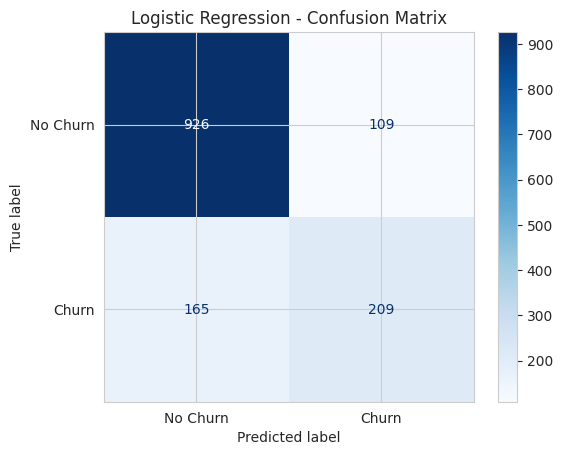

In [53]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [54]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight='balanced',
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [55]:
# Predict churn
rf_pred = rf_model.predict(X_test)

# Predict probability of churn
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions completed!")
print("First 10 predictions:", rf_pred[:10])
print("First 10 churn probabilities:", rf_prob[:10])

Random Forest predictions completed!
First 10 predictions: [0 1 0 0 0 0 0 0 0 0]
First 10 churn probabilities: [0.    0.705 0.075 0.29  0.005 0.385 0.405 0.115 0.    0.435]


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Evaluation")
print("------------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Random Forest Evaluation
------------------------
Accuracy:  0.7828
Precision: 0.6189
Recall:    0.4733
F1-score:  0.5364
ROC-AUC:   0.8232


In [57]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Logistic Regression': [
        accuracy, precision, recall, f1, roc_auc
    ],
    'Random Forest': [
        rf_accuracy, rf_precision, rf_recall, rf_f1, rf_roc_auc
    ]
})

comparison

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.805536,0.782825
1,Precision,0.657233,0.618881
2,Recall,0.558824,0.473262
3,F1-score,0.604046,0.536364
4,ROC-AUC,0.842135,0.823214


In [58]:
!pip install xgboost

In [59]:
from xgboost import XGBClassifier

In [60]:
xgb_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [61]:
# Predict churn
xgb_pred = xgb_model.predict(X_test)

# Predict probability of churn
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost predictions completed!")
print("First 10 predictions:", xgb_pred[:10])
print("First 10 churn probabilities:", xgb_prob[:10])

XGBoost predictions completed!
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]
First 10 churn probabilities: [0.0144771  0.8687383  0.06655761 0.37816286 0.00885646 0.6292069
 0.45367703 0.09763297 0.0184017  0.35557455]


In [62]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_roc_auc = roc_auc_score(y_test, xgb_prob)

print("XGBoost Evaluation")
print("------------------")
print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1-score:  {xgb_f1:.4f}")
print(f"ROC-AUC:   {xgb_roc_auc:.4f}")

XGBoost Evaluation
------------------
Accuracy:  0.8055
Precision: 0.6724
Recall:    0.5214
F1-score:  0.5873
ROC-AUC:   0.8452


In [63]:
final_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Logistic Regression': [
        accuracy, precision, recall, f1, roc_auc
    ],
    'Random Forest': [
        rf_accuracy, rf_precision, rf_recall, rf_f1, rf_roc_auc
    ],
    'XGBoost': [
        xgb_accuracy, xgb_precision, xgb_recall,
        xgb_f1, xgb_roc_auc
    ]
})

final_comparison

,Metric,Logistic Regression,Random Forest,XGBoost
0,Accuracy,0.805536,0.782825,0.805536
1,Precision,0.657233,0.618881,0.672414
2,Recall,0.558824,0.473262,0.521390
3,F1-score,0.604046,0.536364,0.587349
4,ROC-AUC,0.842135,0.823214,0.845165


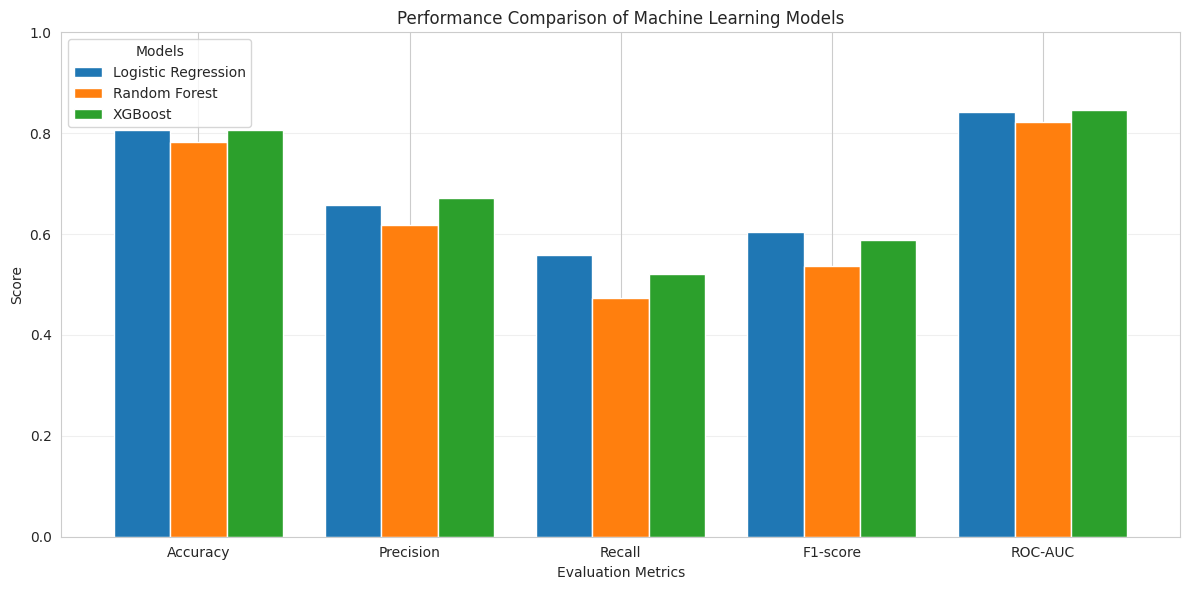

In [64]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']

model_results = {
    'Logistic Regression': [accuracy, precision, recall, f1, roc_auc],
    'Random Forest': [rf_accuracy, rf_precision, rf_recall, rf_f1, rf_roc_auc],
    'XGBoost': [xgb_accuracy, xgb_precision, xgb_recall, xgb_f1, xgb_roc_auc]
}

comparison_df = pd.DataFrame(model_results, index=metrics)

comparison_df.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Performance Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Models')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
comparison_df.to_csv(
    'model_performance_comparison.csv'
)

print("Comparison table saved successfully!")

Comparison table saved successfully!


In [66]:
# Get the trained XGBoost classifier
xgb_classifier = xgb_model.named_steps['classifier']

# Get the fitted preprocessing component
fitted_preprocessor = xgb_model.named_steps['preprocessor']

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance
importance_values = xgb_classifier.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
feature_importance.head(15)

,Feature,Importance
36,cat__Contract_Month-to-month,0.308946
16,cat__InternetService_Fiber optic,0.126685
18,cat__OnlineSecurity_No,0.093034
15,cat__InternetService_DSL,0.051110
27,cat__TechSupport_No,0.041066
38,cat__Contract_Two year,0.037705
37,cat__Contract_One year,0.021638
19,cat__OnlineSecurity_No internet service,0.021247
35,cat__StreamingMovies_Yes,0.021224
1,num__tenure,0.018663


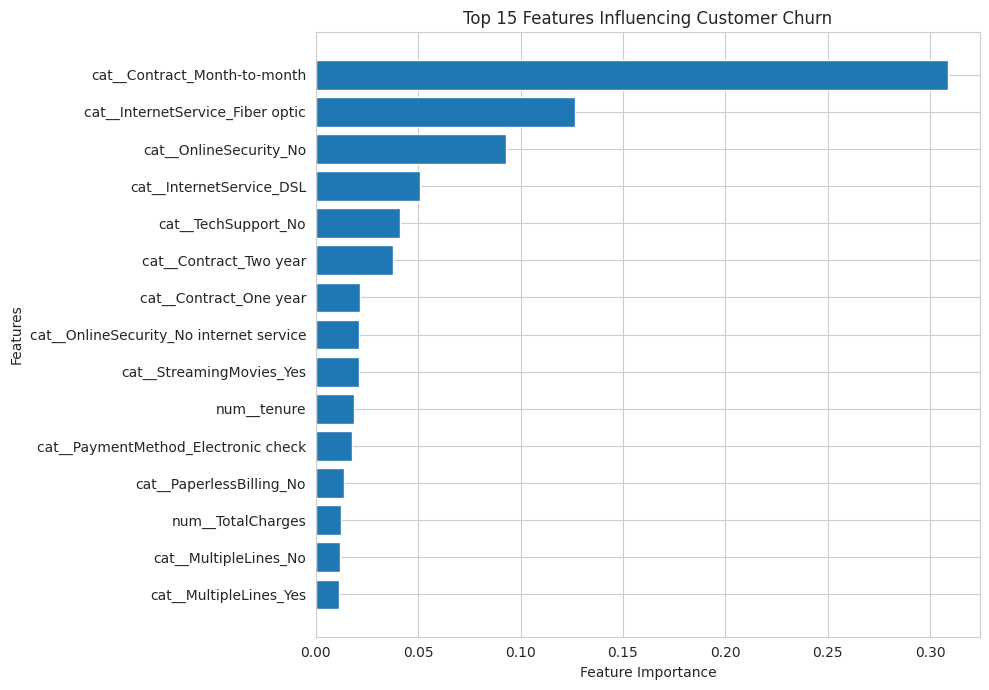

In [67]:
top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 15 Features Influencing Customer Churn')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [68]:
!pip install shap

In [69]:
import shap

print("SHAP imported successfully!")

SHAP imported successfully!


In [70]:
# Transform test data using the fitted preprocessor
X_test_transformed = fitted_preprocessor.transform(X_test)

# Convert transformed data into a DataFrame
X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

# Select 500 test samples for SHAP analysis
X_shap = X_test_transformed_df.sample(
    n=500,
    random_state=42
)

print("SHAP dataset shape:", X_shap.shape)

SHAP dataset shape: (500, 45)


In [71]:
explainer = shap.TreeExplainer(xgb_classifier)

shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


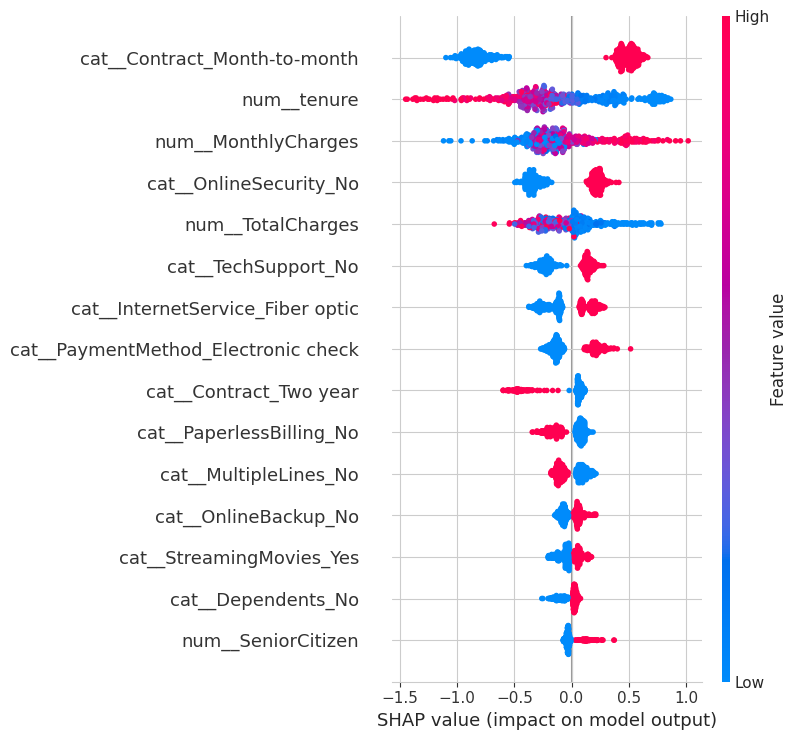

In [72]:
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15
)

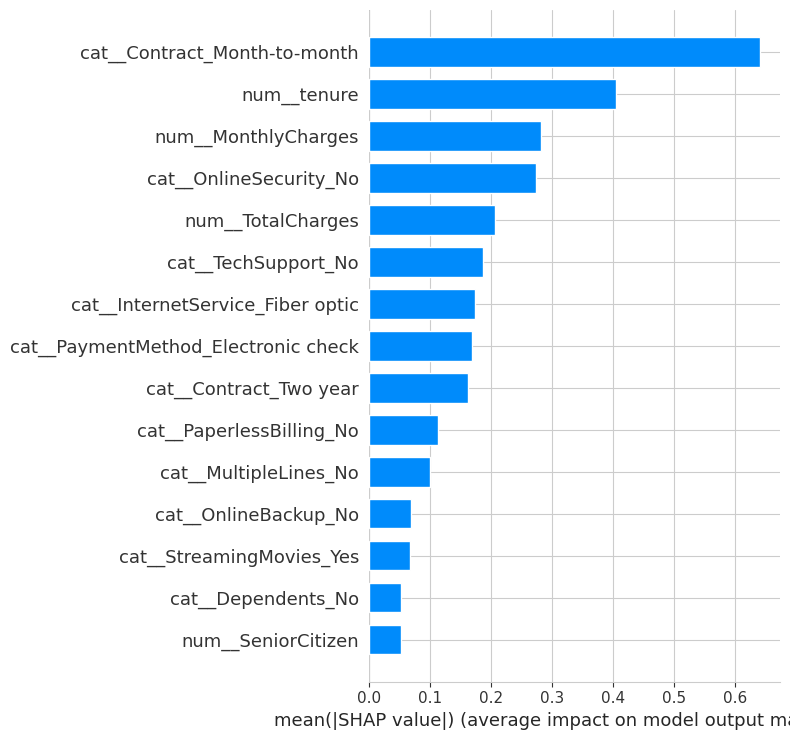

In [73]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type='bar',
    max_display=15
)

In [74]:
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15,
    show=False
)

plt.savefig(
    'shap_summary_plot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type='bar',
    max_display=15,
    show=False
)

plt.savefig(
    'shap_feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

print("SHAP plots saved successfully!")

SHAP plots saved successfully!


SHAP Summary Plot:


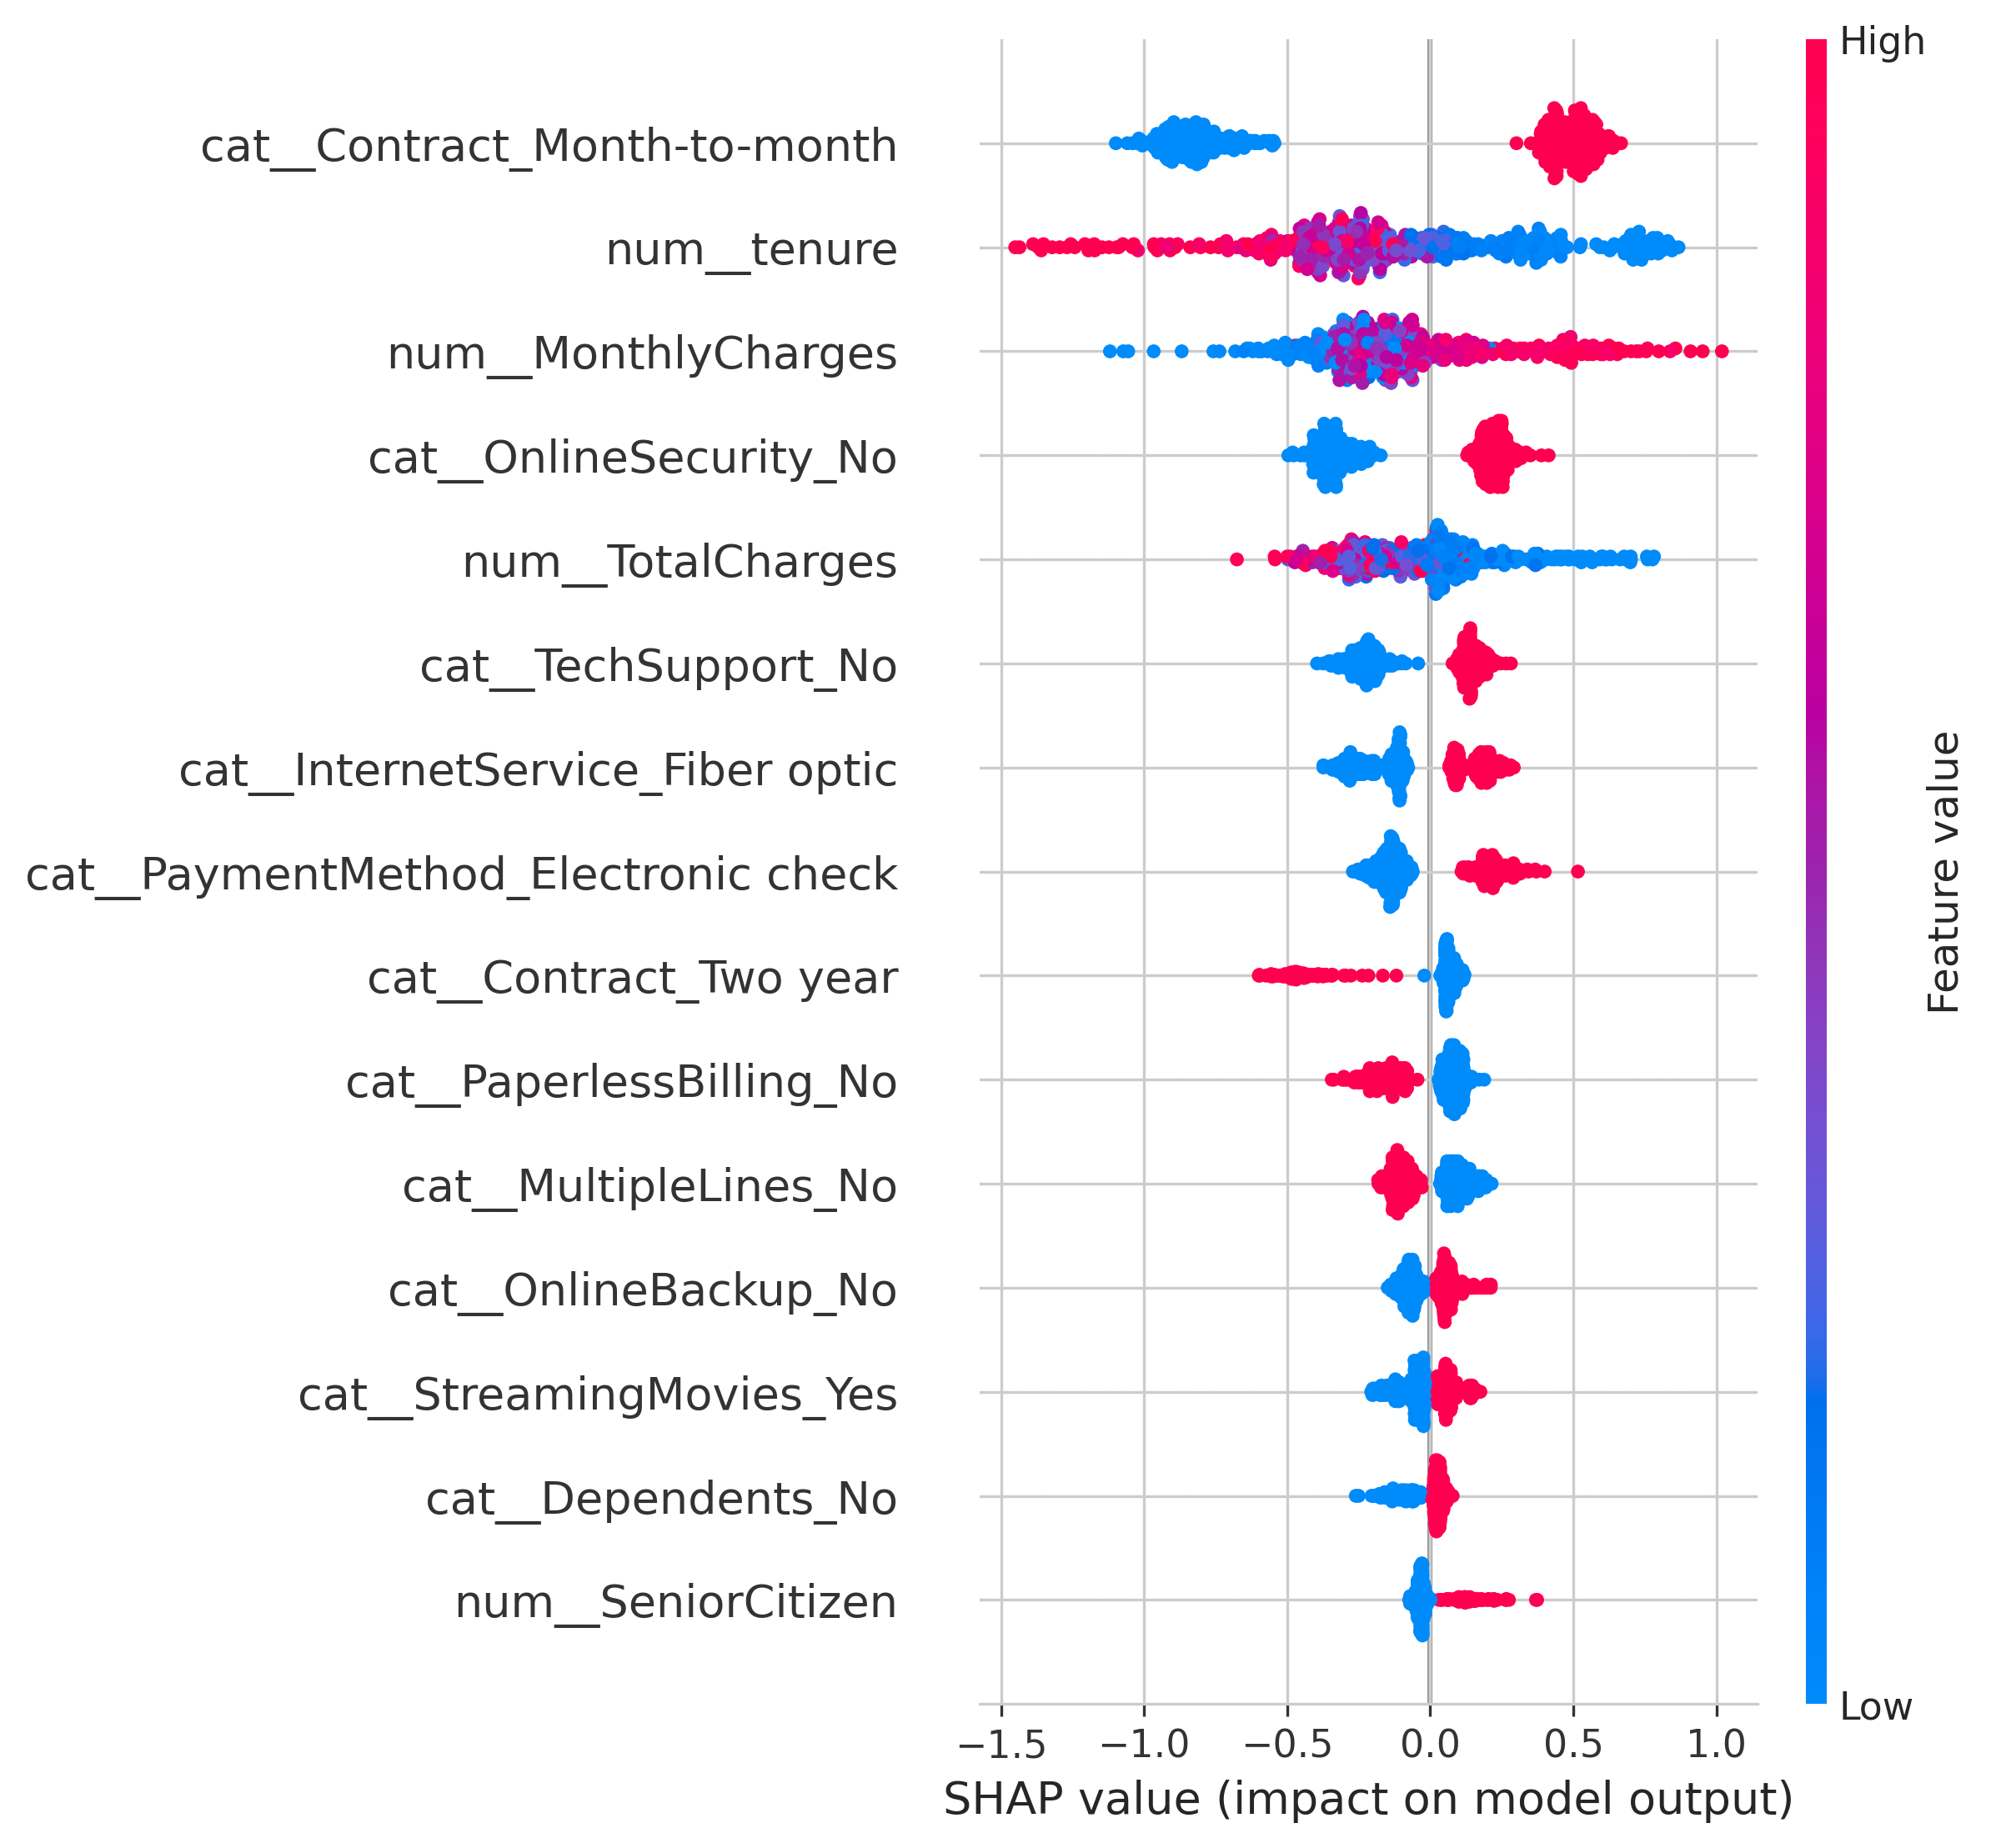

SHAP Feature Importance Plot:


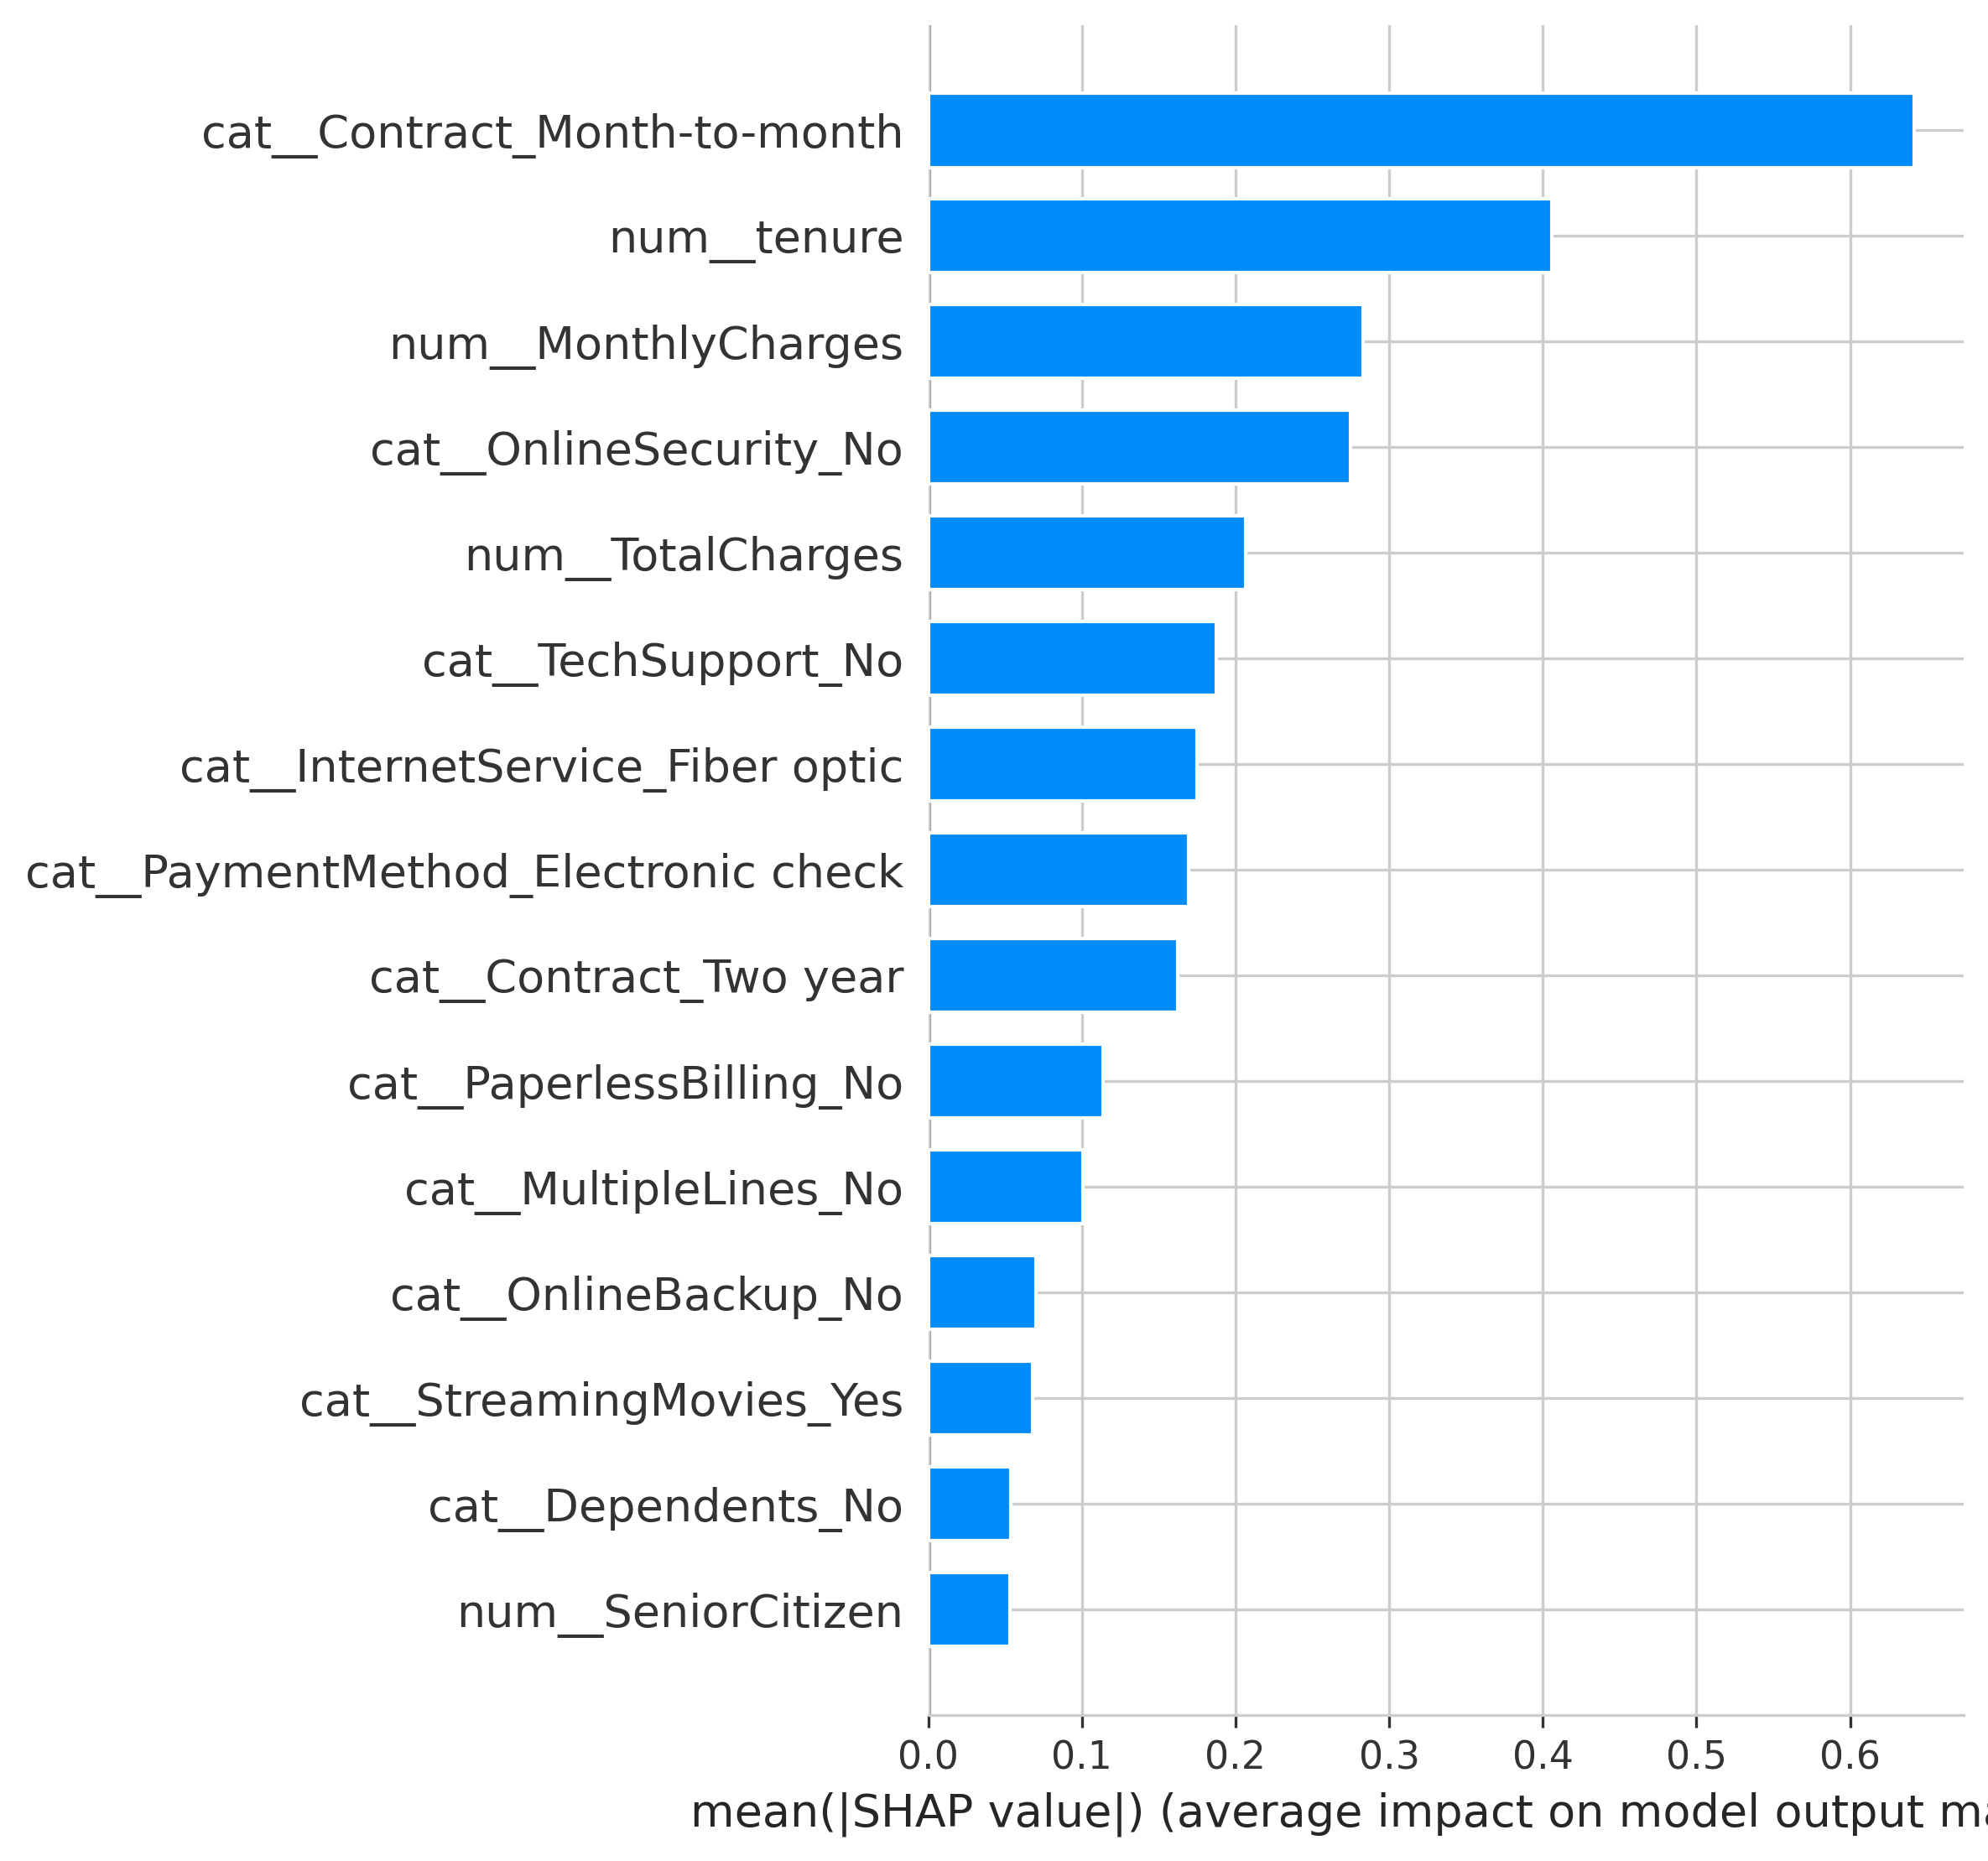

In [75]:
from IPython.display import display, Image

print("SHAP Summary Plot:")
display(Image(filename='shap_summary_plot.png'))

print("SHAP Feature Importance Plot:")
display(Image(filename='shap_feature_importance.png'))

From here


In [76]:
# Calculate mean absolute SHAP values
shap_importance = np.abs(shap_values).mean(axis=0)

# Create a DataFrame
shap_importance_df = pd.DataFrame({
    'Feature': X_shap.columns,
    'Mean_SHAP_Importance': shap_importance
})

# Sort by importance
shap_importance_df = shap_importance_df.sort_values(
    by='Mean_SHAP_Importance',
    ascending=False
)

# Display top 15 features
shap_importance_df.head(15)

,Feature,Mean_SHAP_Importance
36,cat__Contract_Month-to-month,0.641721
1,num__tenure,0.405731
2,num__MonthlyCharges,0.282881
18,cat__OnlineSecurity_No,0.274781
3,num__TotalCharges,0.206406
27,cat__TechSupport_No,0.187732
16,cat__InternetService_Fiber optic,0.174840
43,cat__PaymentMethod_Electronic check,0.169627
38,cat__Contract_Two year,0.162229
39,cat__PaperlessBilling_No,0.113787


In [77]:
shap_importance_df.to_csv(
    'shap_importance_results.csv',
    index=False
)

print("SHAP importance results saved successfully!")

SHAP importance results saved successfully!


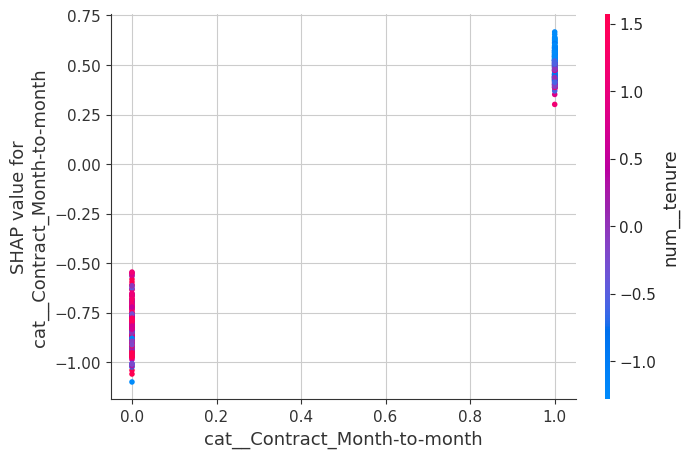

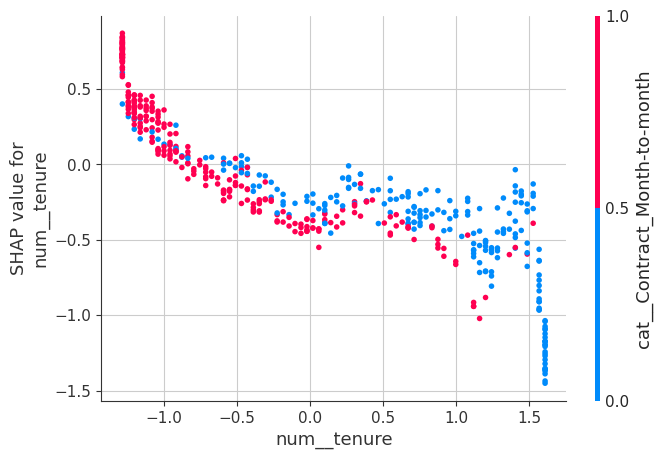

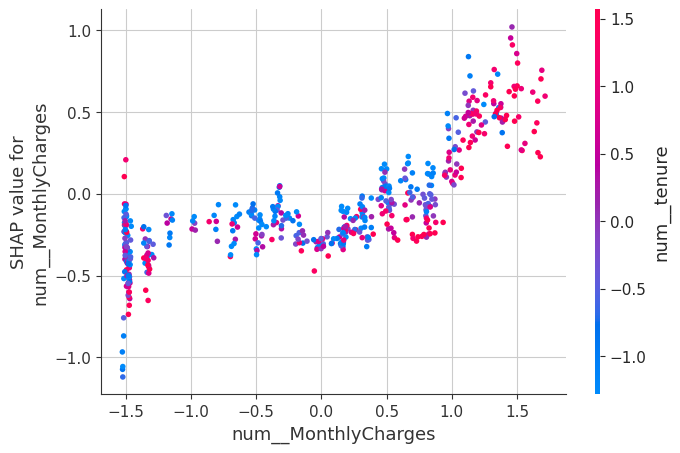

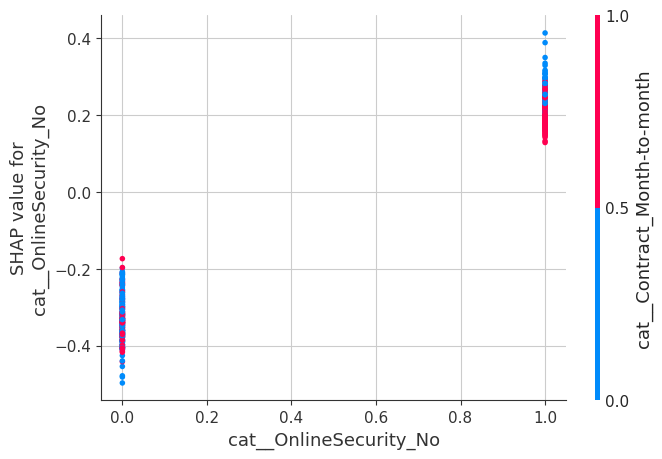

In [78]:
features_to_explain = [
    'cat__Contract_Month-to-month',
    'num__tenure',
    'num__MonthlyCharges',
    'cat__OnlineSecurity_No'
]

for feature in features_to_explain:
    shap.dependence_plot(
        feature,
        shap_values,
        X_shap
    )


## Limitations

1. The study uses a single publicly available telecom customer churn dataset.
2. The dataset may not represent customer behavior across all telecom markets.
3. Only three machine learning algorithms were evaluated.
4. Hyperparameter optimization and cross-validation have not yet been performed.
5. The dataset contains class imbalance, which may affect minority-class prediction.
6. Feature importance and SHAP values indicate predictive contributions, not causal relationships.
7. The models have not been evaluated on an independent external dataset.

## Conclusion

This project investigated customer churn prediction using three machine learning algorithms: Logistic Regression, Random Forest, and XGBoost.

The models were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. Logistic Regression achieved an accuracy of 80.55%, recall of 55.88%, F1-score of 60.40%, and ROC-AUC of 84.21%. XGBoost achieved the highest ROC-AUC of 84.52%, while Random Forest demonstrated comparatively lower performance.

Feature importance and SHAP analysis identified contract type, customer tenure, monthly charges, online security, and total charges as influential predictive features. Month-to-month contract status was the most important feature in both XGBoost feature importance and SHAP analysis.

Overall, the findings demonstrate the potential of machine learning and explainable AI techniques for identifying customers at risk of churn. Further research involving hyperparameter optimization, cross-validation, threshold adjustment, and external validation could improve model performance and reliability.